# Week 9 Homework — QLoRA Fine-Tuning Llama 3 8B + Deployment
**COM SCI-X 455 · Week 9**

> Push to `genai-course/week9/homework/`  |  Domain: video-game scene cards

---

## Setup

In [1]:
!pip install transformers peft bitsandbytes accelerate datasets huggingface_hub gradio matplotlib pandas --quiet

In [2]:
import os, json, re, gc, time, random
from contextlib import nullcontext
import torch, pandas as pd
import matplotlib.pyplot as plt
from google.colab import userdata
from huggingface_hub import login, HfApi, ModelCard
from datasets import Dataset
from transformers import (AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig,
                          Trainer, TrainingArguments, DataCollatorForSeq2Seq)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

HF_TOKEN = userdata.get('HF_TOKEN')          # needs Meta-Llama-3-8B licence accepted on the Hub
login(token=HF_TOKEN)
HF_USER = HfApi().whoami(token=HF_TOKEN)["name"]
BASE_ID = "meta-llama/Meta-Llama-3-8B"
HF_REPO = f"{HF_USER}/llama3-8b-game-scene-qlora"
print("GPU:", torch.cuda.get_device_name(0))
print("Adapter will be pushed to:", HF_REPO)
print("All imports OK")

GPU: Tesla T4
Adapter will be pushed to: giashere0/llama3-8b-game-scene-qlora
All imports OK


## Part 1 — Dataset Preparation and Fine-Tuning

**Domain:** video-game scene cards. Input = a game setting + mood/time/constraints, output = a fixed 6-field card (title, narration for TTS, SDXL image prompt, negative prompt, audio cue, player choices). This is the text stage of my capstone pipeline (Lab 5: Bark + SDXL + GPT-4o).

In [3]:
# ── Dataset builder (Alpaca format)
import json, random, re
from collections import Counter

random.seed(42)

# ── Settings: (title, genre, place, core narration, visuals, sound, npc, object, exit) ──
SETTINGS = [
    ("The Drowned Chapel", "fantasy RPG", "a drowned chapel beneath a lake",
     "Cold water laps at the cracked altar as pale light filters down through the surface above.",
     "flooded stone chapel, shattered stained glass, submerged pews, rays of light through water",
     "dripping water and a distant tolling bell", "a ghostly acolyte", "the sealed reliquary", "the spiral stairs"),
    ("The Orbital Greenhouse", "sci-fi", "an abandoned orbital greenhouse",
     "Vines coil around dead consoles while a failing grow-lamp flickers across the cracked dome.",
     "derelict space station greenhouse, tangled vines, cracked observation dome, flickering grow lights, Earth in the window",
     "creaking hull and a faint ventilation hum", "a maintenance drone", "the seed vault terminal", "the airlock corridor"),
    ("Neo-Osaka Noodle Alley", "cyberpunk", "a rain-soaked noodle alley in Neo-Osaka",
     "Neon signs bleed into the puddles as steam rises from a cramped noodle stall.",
     "cyberpunk alley, neon kanji signs, wet pavement reflections, steaming noodle stall, holographic ads",
     "rain on tin awnings and distant synth bass", "the stall owner", "a discarded data chip", "the elevated train stairs"),
    ("Overpass Settlement", "post-apocalyptic survival", "a settlement under a collapsed highway overpass",
     "Scrap-metal tents cling to broken concrete while smoke curls from a communal fire.",
     "post-apocalyptic settlement, collapsed highway, rusted cars, scrap tents, campfire smoke",
     "wind through rebar and low murmuring voices", "a wary scavenger", "the locked supply truck", "the cracked off-ramp"),
    ("The Silent Nursery", "survival horror", "a candlelit nursery in an abandoned manor",
     "Moonlight crosses a row of antique cribs where a music box plays on its own.",
     "gothic manor nursery, antique cribs, porcelain dolls, dusty moonlight, peeling wallpaper",
     "a slow music box melody and creaking floorboards", "a faceless governess", "the music box", "the narrow servant door"),
    ("Last Chance Saloon", "western", "a dusty frontier saloon at the edge of town",
     "Swinging doors creak as dust drifts through shafts of light over a half-empty bar.",
     "wild west saloon interior, swinging doors, wooden bar, whiskey bottles, dust in sunbeams",
     "a tinny piano and spurs on floorboards", "the bartender", "a torn wanted poster", "the back alley"),
    ("The Stormbound Galleon", "pirate adventure", "the deck of a storm-tossed galleon",
     "Waves crash over the rail as the mainsail strains against the wind.",
     "pirate galleon deck, towering waves, torn sails, swinging lanterns, rope rigging",
     "roaring wind and creaking timber", "the first mate", "the captain's locked chest", "the hatch to the hold"),
    ("The Sun Tomb", "action adventure", "a sunlit tomb antechamber",
     "Golden light spills across hieroglyphs carved into towering sandstone pillars.",
     "ancient Egyptian tomb antechamber, hieroglyph walls, sandstone pillars, golden light, scattered relics",
     "echoing footsteps and shifting sand", "a mummified guardian", "the pressure-plate floor", "the collapsed entrance"),
    ("The Clockwork Observatory", "steampunk", "a clockwork observatory atop a sea cliff",
     "Brass gears turn slowly beneath an enormous telescope aimed at the stars.",
     "steampunk observatory, brass gears, giant telescope, copper pipes, cliffside windows, starry sky",
     "ticking gears and hissing steam", "an absent-minded inventor", "the star chart table", "the cliff elevator"),
    ("Embassy Rooftop", "stealth spy thriller", "a rooftop above an embassy gala",
     "Music drifts up from the ballroom below while searchlights sweep the glass skylights.",
     "city rooftop at night, embassy skylights, searchlight beams, ventilation ducts, glittering skyline",
     "muffled string quartet and distant sirens", "a bored security guard", "the vent cover", "the fire escape"),
    ("Lantern Market", "cozy village sim", "a lantern-lit village market at evening",
     "Paper lanterns sway above stalls piled with fruit, bread, and handmade charms.",
     "cozy village market, paper lanterns, wooden stalls, fresh bread, handmade charms, cobblestones",
     "chatter, laughter, and a street fiddle", "a cheerful baker", "the mystery seed stall", "the quiet footpath home"),
    ("Pressure Habitat", "underwater sci-fi", "a deep-sea research habitat",
     "Dark water presses against the viewport while status lights pulse along the corridor.",
     "deep sea research habitat, thick viewport glass, bioluminescent creatures, metal corridor, warning lights",
     "muffled sonar pings and groaning metal", "the station biologist", "the flooded lab door", "the escape pod bay"),
    ("The Winter Feast Hall", "viking saga", "a longhouse feast hall in deep winter",
     "Firelight dances on carved beams as warriors raise horns around a long table.",
     "viking longhouse, roaring hearth, carved wooden beams, feast table, fur cloaks, snow outside",
     "crackling fire and booming laughter", "the jarl", "the oath-ring on the table", "the frozen courtyard door"),
    ("Bamboo Shrine Path", "samurai drama", "a bamboo grove shrine path",
     "Tall bamboo sways over a moss-covered stone path leading to a small shrine.",
     "bamboo forest, stone lantern path, small wooden shrine, mist, moss, torii gate",
     "rustling bamboo and a distant temple gong", "a wandering monk", "the shrine offering box", "the path back to the village"),
    ("The Velvet Back Office", "detective noir", "a smoky jazz club back office",
     "Cigarette smoke curls under a desk lamp as a saxophone leaks through the wall.",
     "noir jazz club back office, desk lamp, cigarette smoke, venetian blind shadows, rain on window",
     "muted saxophone and rain on glass", "the club owner", "the locked filing cabinet", "the stage door"),
    ("Hangar Bay Seven", "mech combat", "a hangar bay before launch",
     "Sparks fall from welding rigs as a towering mech is fueled for deployment.",
     "mech hangar bay, giant robot, welding sparks, gantry cranes, hazard stripes, ground crew",
     "clanging tools and a pre-launch countdown", "the chief mechanic", "the weapons loadout console", "the launch catapult"),
    ("Snowbound Cabin", "survival", "a snowbound mountain cabin",
     "Wind rattles the shutters while the last logs smolder in a small stone fireplace.",
     "snowbound mountain cabin interior, stone fireplace, frost on windows, wooden table, wool blankets",
     "howling wind and crackling embers", "a stranded hiker", "the empty firewood crate", "the frozen front door"),
    ("The Floating Library", "wizard academy", "a tower library with floating books",
     "Hundreds of books drift between spiral shelves as candlelight flickers overhead.",
     "magical tower library, floating books, spiral bookshelves, hovering candles, arched windows",
     "rustling pages and soft chiming", "the head librarian", "the forbidden shelf", "the winding staircase"),
    ("Overgrown Temple Stairs", "jungle exploration", "an overgrown temple stairway",
     "Roots split the ancient steps as howler monkeys call from the canopy.",
     "jungle temple stairway, giant roots, mossy stone, hanging vines, shafts of green light, stone idols",
     "insect chorus and distant monkey calls", "a rival treasure hunter", "the carved idol", "the vine-choked trail"),
    ("Oasis Caravan Camp", "desert adventure", "a caravan oasis at the edge of the dunes",
     "Camels rest beside a still pool as tents ripple in the warm desert wind.",
     "desert oasis camp, palm trees, still water, caravan tents, sand dunes, camels",
     "soft wind and jingling camel bells", "the caravan master", "the buried water jar", "the open dunes"),
    ("The Haunted Midway", "horror comedy", "a haunted carnival midway",
     "Rusted rides creak overhead as a lone ticket booth glows beneath flickering bulbs.",
     "abandoned carnival midway, rusted ferris wheel, flickering bulbs, ticket booth, scattered popcorn",
     "warped calliope music and creaking metal", "a grinning ticket seller", "the broken fortune machine", "the front gate"),
    ("Cryo Bay Awakening", "sci-fi", "a colony ship cryo bay",
     "Frost clears from a row of pods as emergency lights wash the corridor red.",
     "colony ship cryo bay, frosted pods, red emergency lights, mist on floor, sterile metal walls",
     "rhythmic alarm and hissing coolant", "the ship's AI", "the stuck pod door", "the central corridor"),
    ("Goblin Market", "dark fantasy", "a goblin market beneath a stone bridge",
     "Crooked stalls glitter with stolen trinkets under a ceiling of hanging lanterns.",
     "goblin market under stone bridge, crooked stalls, stolen trinkets, hanging lanterns, murky shadows",
     "haggling voices and clinking coins", "a one-eyed goblin merchant", "the cursed locket", "the slippery stairs to the road"),
    ("The Castle War Room", "strategy", "a medieval castle war room",
     "Candles gutter beside a vast map table covered in carved wooden banners.",
     "medieval castle war room, large map table, wooden banner figures, candles, stone walls, tapestries",
     "low murmured debate and a crackling hearth", "the old general", "the enemy supply map", "the heavy oak door"),
    ("The Rooftop Garden", "slice-of-life", "a rooftop garden above a busy street",
     "Tomato vines climb a patched trellis while the city hums quietly below.",
     "rooftop garden, tomato vines, patched trellis, string lights, city skyline, potted herbs",
     "distant traffic and buzzing bees", "a retired neighbor", "the locked tool shed", "the rusty stairwell"),
]

MOODS = {
    "eerie":      ("Something about the stillness feels watched.", "unsettling atmosphere, pale fog", "low drone with sparse high notes"),
    "triumphant": ("A hard-won sense of victory fills the air.", "radiant golden highlights, heroic framing", "swelling brass and steady drums"),
    "melancholy": ("Everything here whispers of what has been lost.", "muted blue palette, soft haze", "slow solo piano"),
    "tense":      ("Every sound makes your pulse climb.", "harsh contrast, deep shadows", "pulsing low strings and a ticking rhythm"),
    "whimsical":  ("It all feels like a story waiting to be told.", "playful colors, storybook charm", "light pizzicato strings and chimes"),
    "serene":     ("For a moment, the world feels perfectly calm.", "soft diffuse light, gentle pastel tones", "warm ambient pads and soft flute"),
    "ominous":    ("A quiet dread gathers just out of sight.", "looming silhouettes, dark vignette", "rumbling bass and distant choir"),
    "frantic":    ("There is no time to waste.", "motion blur, dynamic angle, high contrast", "fast percussion and rising synths"),
}

TIMES = {
    "dawn":     ("Dawn light creeps in slowly.", "soft dawn light", "at Dawn"),
    "midday":   ("The midday sun hangs high.", "bright midday light", "at Midday"),
    "dusk":     ("Dusk deepens the shadows.", "orange dusk glow", "at Dusk"),
    "midnight": ("Midnight has settled in.", "dim moonlit lighting", "at Midnight"),
    "storm":    ("A storm rages outside.", "flashes of lightning, heavy rain", "in the Storm"),
}

CONSTRAINTS = ["exactly two player choices", "narration must be one sentence",
               "child-friendly, ages 8+", "include a hidden clue in the image prompt"]
GENTLE = ["whimsical", "serene", "triumphant", "melancholy"]

PHRASINGS = [
    "Write a game scene card for a {genre} game set in {place}.",
    "Create a scene card (narration, image prompt, audio cue, choices) for a {genre} game. Location: {place}.",
    "Generate a structured scene card for {place} in a {genre} game.",
    "Design one playable scene set in {place} for a {genre} game using the scene card format.",
]

NEG_BASE = "text, watermark, blurry, extra limbs, low quality"
STYLE = "highly detailed digital painting, cinematic composition, 16:9"

def cap(s): return s[0].upper() + s[1:]

def build(setting, mood, time, difficulty, constraint, phrasing_i):
    title, genre, place, core, visuals, sound, npc, obj, exit_ = setting
    mood_tail, mood_vis, mood_aud = MOODS[mood]
    time_line, time_vis, time_title = TIMES[time]
    neg = NEG_BASE
    narration = f"{core} {time_line} {mood_tail}"
    img = [visuals, time_vis, mood_vis]
    audio = f"{sound}; {mood_aud}"
    choices = [f"Speak with {npc}.", f"Examine {obj}.", f"Retreat through {exit_}."]
    inp = f"Mood: {mood}."
    if difficulty != "easy":
        inp += f" Time: {time}."
    if difficulty == "hard":
        inp += f" NPC in scene: {npc}. Constraint: {constraint}."
        img.append(f"{npc} standing in the foreground")
        narration = f"{core} {time_line} {cap(npc)} watches you. {mood_tail}"
        if constraint == "exactly two player choices":
            choices = choices[:2]
        elif constraint == "narration must be one sentence":
            narration = core
        elif constraint == "child-friendly, ages 8+":
            narration = f"{core} {time_line} {cap(npc)} gives you a small, friendly wave."
            img.append("storybook illustration, soft colors")
            neg += ", gore, blood, horror"
            audio = f"{sound}; gentle playful strings"
        elif constraint == "include a hidden clue in the image prompt":
            img.append(f"a subtle hidden clue near {obj}")
    img.append(STYLE)
    out = (f"SCENE TITLE: {title} {time_title}\n"
           f"NARRATION: {narration}\n"
           f"IMAGE PROMPT: {', '.join(img)}\n"
           f"NEGATIVE PROMPT: {neg}\n"
           f"AUDIO CUE: {audio}\n"
           f"PLAYER CHOICES:\n" + "\n".join(f"{i+1}. {c}" for i, c in enumerate(choices)))
    instr = PHRASINGS[phrasing_i].format(genre=genre, place=place)
    return {"instruction": instr, "input": inp, "output": out}, difficulty

if __name__ == "__main__":
    pairs = [(s_, m_) for s_ in SETTINGS for m_ in MOODS]
    random.shuffle(pairs)
    easy_pairs, rest = pairs[:77], pairs[77:]
    rest = rest + random.sample(pairs, len(pairs))
    plan = [(p, "easy") for p in easy_pairs] + \
           [(p, "medium") for p in rest[:77]] + [(p, "hard") for p in rest[77:153]]
    rows, diffs, seen = [], [], set()
    for (s, m), d in plan:
        c, t = None, "dusk"
        if d != "easy":
            t = random.choice(list(TIMES))
        if d == "hard":
            c = random.choice(CONSTRAINTS)
            if c == "child-friendly, ages 8+" and m not in GENTLE:
                m = random.choice(GENTLE)
        for pi in random.sample(range(len(PHRASINGS)), len(PHRASINGS)):
            row, dd = build(s, m, t, d, c, pi)
            key = (row["instruction"], row["input"])
            if key not in seen:
                break
        else:
            raise RuntimeError("could not make a unique row")
        seen.add(key); rows.append(row); diffs.append(dd)
    order = list(range(len(rows))); random.shuffle(order)
    rows = [rows[i] for i in order]; diffs = [diffs[i] for i in order]
    with open("game_scenes_dataset.jsonl", "w") as f:
        for r in rows: f.write(json.dumps(r, ensure_ascii=False) + "\n")
    # checks
    assert not any(re.search(r"[\w.]+@[\w.]+|\d{3}[-. ]\d{3}[-. ]\d{4}", r["output"] + r["input"]) for r in rows)
    wc = [len(re.search(r"NARRATION: (.*)", r["output"]).group(1).split()) for r in rows]
    print(len(rows), Counter(diffs), "narration words min/max", min(wc), max(wc))
    one = [r for r in rows if "one sentence" in r["input"]]
    print("one-sentence rows:", len(one), "max words:", max(len(re.search(r"NARRATION: (.*)", r["output"]).group(1).split()) for r in one))


230 Counter({'easy': 77, 'medium': 77, 'hard': 76}) narration words min/max 10 33
one-sentence rows: 17 max words: 15


In [4]:
# ── Load, inspect, split ──
rows = [json.loads(l) for l in open("game_scenes_dataset.jsonl")]
assert len(rows) >= 200 and all(set(r) == {"instruction", "input", "output"} for r in rows)
print("Examples:", len(rows))
print("Difficulty mix (by input detail): easy =", sum("Time:" not in r["input"] for r in rows),
      "| medium =", sum("Time:" in r["input"] and "Constraint:" not in r["input"] for r in rows),
      "| hard =", sum("Constraint:" in r["input"] for r in rows))
print("\n--- sample ---")
print(rows[0]["instruction"], "|", rows[0]["input"]); print(rows[0]["output"])

random.seed(42); random.shuffle(rows)
n_val = max(20, int(0.1 * len(rows)))
train_rows, val_rows = rows[n_val:], rows[:n_val]
print(f"\nTrain: {len(train_rows)} | Val: {len(val_rows)}")

Examples: 230
Difficulty mix (by input detail): easy = 77 | medium = 77 | hard = 76

--- sample ---
Design one playable scene set in a rooftop garden above a busy street for a slice-of-life game using the scene card format. | Mood: triumphant.
SCENE TITLE: The Rooftop Garden at Dusk
NARRATION: Tomato vines climb a patched trellis while the city hums quietly below. Dusk deepens the shadows. A hard-won sense of victory fills the air.
IMAGE PROMPT: rooftop garden, tomato vines, patched trellis, string lights, city skyline, potted herbs, orange dusk glow, radiant golden highlights, heroic framing, highly detailed digital painting, cinematic composition, 16:9
NEGATIVE PROMPT: text, watermark, blurry, extra limbs, low quality
AUDIO CUE: distant traffic and buzzing bees; swelling brass and steady drums
PLAYER CHOICES:
1. Speak with a retired neighbor.
2. Examine the locked tool shed.
3. Retreat through the rusty stairwell.

Train: 207 | Val: 23


In [5]:
# ── Prompt template + tokenization (loss only on the response) ───────
PROMPT = ("Below is an instruction that describes a task, paired with an input that provides "
          "further context. Write a response that completes the request.\n\n"
          "### Instruction:\n{instruction}\n\n### Input:\n{input}\n\n### Response:\n")
MAX_LEN = 512

tokenizer = AutoTokenizer.from_pretrained(BASE_ID, token=HF_TOKEN)
tokenizer.pad_token = tokenizer.eos_token

def tokenize(ex):
    prompt_ids = tokenizer(PROMPT.format(**{k: ex[k] for k in ("instruction", "input")}))["input_ids"]
    resp_ids = tokenizer(ex["output"], add_special_tokens=False)["input_ids"] + [tokenizer.eos_token_id]
    ids = (prompt_ids + resp_ids)[:MAX_LEN]
    labels = ([-100] * len(prompt_ids) + resp_ids)[:MAX_LEN]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}

train_ds = Dataset.from_list(train_rows).map(tokenize, remove_columns=["instruction", "input", "output"])
val_ds = Dataset.from_list(val_rows).map(tokenize, remove_columns=["instruction", "input", "output"])
print("Max tokens in train set:", max(len(x) for x in train_ds["input_ids"]))

config.json:   0%|          | 0.00/654 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.6k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/73.0 [00:00<?, ?B/s]

Map:   0%|          | 0/207 [00:00<?, ? examples/s]

Map:   0%|          | 0/23 [00:00<?, ? examples/s]

Max tokens in train set: 298


In [6]:
# ── QLoRA model: 4-bit NF4 + double quantization
bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
model = AutoModelForCausalLM.from_pretrained(BASE_ID, quantization_config=bnb_config,
                                             device_map="auto", token=HF_TOKEN)
model.config.use_cache = False
model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(r=16, lora_alpha=32, target_modules=["q_proj", "v_proj"],
                         lora_dropout=0.05, bias="none", task_type="CAUSAL_LM")
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable params: {trainable:,} of {total:,} ({100 * trainable / total:.4f}%)")

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/177 [00:00<?, ?B/s]

trainable params: 6,815,744 || all params: 8,037,076,992 || trainable%: 0.0848
Trainable params: 6,815,744 of 4,547,416,064 (0.1499%)


In [9]:
# ── Train: 3 epochs, lr 2e-4, batch size 2 ───
args = TrainingArguments(
    output_dir="qlora-out", num_train_epochs=3, learning_rate=2e-4,
    per_device_train_batch_size=2, per_device_eval_batch_size=2,
    fp16=True, optim="paged_adamw_8bit", lr_scheduler_type="cosine", warmup_steps=10,
    logging_steps=10, eval_strategy="steps", eval_steps=25, save_strategy="no",
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    report_to="none", seed=42,
)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  data_collator=DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100))
t0 = time.time()
train_result = trainer.train()
print(f"Training time: {(time.time() - t0) / 60:.1f} min")

Step,Training Loss,Validation Loss
25,1.761644,1.151731
50,0.733937,0.643411
75,0.508533,0.315171
100,0.246721,0.192551
125,0.105366,0.109947
150,0.056620,0.057667
175,0.033576,0.043199
200,0.021412,0.020878
225,0.011880,0.018149
250,0.006874,0.012631


Training time: 12.5 min


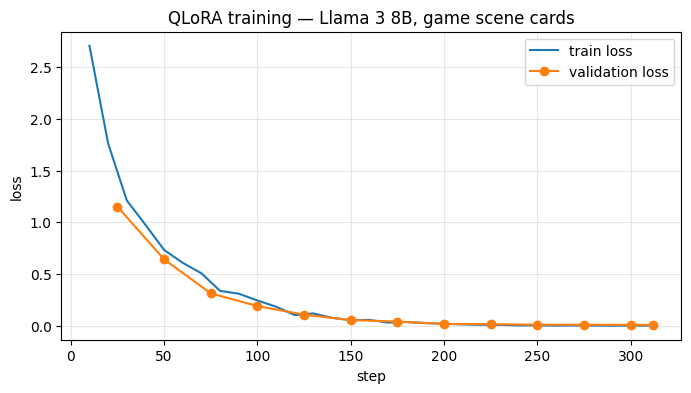

Training Loss,Validation Loss,Step
0.004384,0.012062,312


TRAINING METRICS
Trainable parameters:   6,815,744
Final training loss:    0.0044
Final validation loss:  0.0121
Loss decreased:         True  (1.892 -> 0.004)


In [10]:
# ── Loss curves + training metrics ──
log = trainer.state.log_history
tr = [(l["step"], l["loss"]) for l in log if "loss" in l]
ev = [(l["step"], l["eval_loss"]) for l in log if "eval_loss" in l]

plt.figure(figsize=(8, 4))
plt.plot(*zip(*tr), label="train loss")
plt.plot(*zip(*ev), marker="o", label="validation loss")
plt.xlabel("step"); plt.ylabel("loss"); plt.title("QLoRA training — Llama 3 8B, game scene cards")
plt.legend(); plt.grid(alpha=0.3); plt.savefig("loss_curves.png", dpi=150, bbox_inches="tight"); plt.show()

final_train_loss = tr[-1][1]
final_val_loss = trainer.evaluate()["eval_loss"]
first_avg = sum(v for _, v in tr[:3]) / 3
last_avg = sum(v for _, v in tr[-3:]) / 3
print("=" * 40)
print("TRAINING METRICS")
print("=" * 40)
print(f"Trainable parameters:   {trainable:,}")
print(f"Final training loss:    {final_train_loss:.4f}")
print(f"Final validation loss:  {final_val_loss:.4f}")
print(f"Loss decreased:         {last_avg < first_avg}  ({first_avg:.3f} -> {last_avg:.3f})")

In [11]:
# ── Push adapter + model card to the Hub
model.push_to_hub(HF_REPO, token=HF_TOKEN)
tokenizer.push_to_hub(HF_REPO, token=HF_TOKEN)

card = f"""---
base_model: {BASE_ID}
library_name: peft
license: llama3
tags: [qlora, lora, peft, video-games, scene-generation]
---
# llama3-8b-game-scene-qlora

**Base model:** `{BASE_ID}` · **Method:** QLoRA (4-bit NF4, double quantization), LoRA r=16, alpha=32 on q_proj/v_proj

## Domain
Video-game scene cards: given a game setting plus mood, time of day, NPC and constraints, the model writes a
6-field card (SCENE TITLE, NARRATION, IMAGE PROMPT, NEGATIVE PROMPT, AUDIO CUE, PLAYER CHOICES) used by a
text-to-speech + Stable Diffusion capstone pipeline.

## Dataset
{len(rows)} Alpaca-format examples ({len(train_rows)} train / {len(val_rows)} validation), no PII. Built programmatically from
24 hand-written game settings x 8 moods x 5 times of day x 4 constraint types, at three difficulty levels
(mood only / mood + time / mood + time + NPC + constraint). Synthetic, so style is more uniform than human-written data.

## Training
3 epochs, lr 2e-4, batch size 2, fp16, paged AdamW 8-bit. Final train loss {final_train_loss:.4f}, validation loss {final_val_loss:.4f},
{trainable:,} trainable parameters.

## Usage
Load the base model in 4-bit and attach this adapter with `PeftModel.from_pretrained`. Use the Alpaca prompt template
(### Instruction / ### Input / ### Response).

## Limitations
Trained on 24 settings only; outputs for very different genres or long requests may drift from the format.
"""
ModelCard(card).push_to_hub(HF_REPO, token=HF_TOKEN)
print("Published:", f"https://huggingface.co/{HF_REPO}")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   2%|2         |  561kB / 27.3MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mp_w47bk4i/tokenizer.json: 100%|##########| 17.2MB / 17.2MB            

Validating                    :           |   0%            

Published: https://huggingface.co/giashere0/llama3-8b-game-scene-qlora


## Part 2 — Before/After Inference Comparison

In [12]:
# ── 10 domain-specific test prompts
TEST_PROMPTS = [
    {"instruction": "Write a game scene card for a cozy fantasy game set in a clockwork bakery in a floating city.",
     "input": "Mood: whimsical."},
    {"instruction": "Write a game scene card for a horror game set in an arcade during the graveyard shift.",
     "input": "Mood: eerie. Time: midnight."},
    {"instruction": "Generate a structured scene card for a frozen Antarctic research outpost in a survival game.",
     "input": "Mood: tense. Time: storm."},
    {"instruction": "Create a scene card (narration, image prompt, audio cue, choices) for a fantasy game. Location: a dragon's treasure vault.",
     "input": "Mood: ominous. Time: dusk. NPC in scene: a sleeping dragon. Constraint: exactly two player choices."},
    {"instruction": "Design one playable scene set in a luxury express train carriage for a mystery game using the scene card format.",
     "input": "Mood: tense. Time: midnight. NPC in scene: a nervous conductor. Constraint: include a hidden clue in the image prompt."},
    {"instruction": "Write a game scene card for a fantasy game set in a witch's greenhouse in a swamp.",
     "input": "Mood: serene. Time: dawn. NPC in scene: the witch's apprentice. Constraint: child-friendly, ages 8+."},
    {"instruction": "Generate a structured scene card for a barber shop on a space station in a sci-fi comedy game.",
     "input": "Mood: whimsical. Time: midday."},
    {"instruction": "Write a game scene card for a plague doctor's clinic in a historical drama game.",
     "input": "Mood: melancholy. Time: dusk. NPC in scene: a feverish patient. Constraint: narration must be one sentence."},
    {"instruction": "Create a scene card (narration, image prompt, audio cue, choices) for a sky-pirate game. Location: an airship docking tower.",
     "input": "Mood: frantic. Time: storm."},
    {"instruction": "Write a game scene card for a sci-fi game set in a roadside diner at the end of the universe.",
     "input": "Mood: serene."},
]

model.eval()
model.config.use_cache = True

def generate(p, use_adapter=True):
    inputs = tokenizer(PROMPT.format(**p), return_tensors="pt").to(model.device)
    ctx = nullcontext() if use_adapter else model.disable_adapter()
    with ctx, torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=300, do_sample=False,
                             pad_token_id=tokenizer.eos_token_id)
    text = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return text.split("###")[0].strip()

MARKERS = ["SCENE TITLE:", "NARRATION:", "IMAGE PROMPT:", "NEGATIVE PROMPT:", "AUDIO CUE:", "PLAYER CHOICES:", "1."]
def format_score(text):
    return sum(m in text for m in MARKERS) / len(MARKERS)

results = []
for i, p in enumerate(TEST_PROMPTS, 1):
    base_out, tuned_out = generate(p, use_adapter=False), generate(p, use_adapter=True)
    results.append({"id": i, **p, "base": base_out, "tuned": tuned_out,
                    "base_format": format_score(base_out), "tuned_format": format_score(tuned_out)})
    print("=" * 70); print(f"T{i}: {p['instruction']}\n    {p['input']}")
    print("-" * 30, "BASE", "-" * 30); print(base_out)
    print("-" * 30, "FINE-TUNED", "-" * 30); print(tuned_out)

json.dump(results, open("comparison_outputs.json", "w"), indent=2)
print("\nSaved comparison_outputs.json")

[transformers] Both `max_new_tokens` (=300) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=300) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=300) and `

T1: Write a game scene card for a cozy fantasy game set in a clockwork bakery in a floating city.
    Mood: whimsical.
------------------------------ BASE ------------------------------
A cozy fantasy game set in a clockwork bakery in a floating city. The player is a baker who must bake cakes for the city's residents. The player must collect ingredients and bake cakes to earn points. The player must also avoid obstacles such as falling cakes and angry customers. The game is whimsical and has a light-hearted tone. The player must use their wits and skills to succeed in the game.
------------------------------ FINE-TUNED ------------------------------
SCENE TITLE: The Clockwork Bakery at Dusk
NARRATION: Rows of spinning loaves vanish into a chimney as a small dragon watches you. Dusk deepens the shadows. It all feels like a story waiting to be told.
IMAGE PROMPT: floating clockwork bakery, spinning loaves, chimneys, copper gears, glittering windows, orange dusk glow, playful colors, stor

[transformers] Both `max_new_tokens` (=300) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=300) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


T2: Write a game scene card for a horror game set in an arcade during the graveyard shift.
    Mood: eerie. Time: midnight.
------------------------------ BASE ------------------------------
A game scene card for a horror game set in an arcade during the graveyard shift. Mood: eerie. Time: midnight.
------------------------------ FINE-TUNED ------------------------------
SCENE TITLE: The Graveyard Shift at Midnight
NARRATION: Neon signs bleed into the window glass as the old arcade sounds drift in from the other room. Midnight has settled in. Something about the stillness feels watched.
IMAGE PROMPT: vintage arcade, glass window, neon signs, frosted windows, frosted glass, flashing coin dispensers, dim moonlit lighting, unsettling atmosphere, pale fog, highly detailed digital painting, cinematic composition, 16:9
NEGATIVE PROMPT: text, watermark, blurry, extra limbs, low quality
AUDIO CUE: warped coin speaker and distant street noise; low drone with sparse high notes
PLAYER CHOICES:
1.

[transformers] Both `max_new_tokens` (=300) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=300) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


T3: Generate a structured scene card for a frozen Antarctic research outpost in a survival game.
    Mood: tense. Time: storm.
------------------------------ BASE ------------------------------
The card should include a description of the scene, a list of objects, and a list of characters. The scene should be set in a research outpost in Antarctica, where the player is stranded during a storm. The objects should include a map, a radio, and a first aid kit. The characters should include the player, a scientist, and a polar bear. The mood should be tense, and the time should be stormy.
------------------------------ FINE-TUNED ------------------------------
SCENE TITLE: The Frozen Outpost in the Storm
NARRATION: Wind howls through cracks in the frozen wall while a storm rages outside. Every sound makes your pulse climb.
IMAGE PROMPT: frozen antarctic research outpost, cracked window, snow outside, dim lights, scattered lab equipment, flashes of lightning, heavy rain, harsh contrast, deep

... (10 outputs left out)

[transformers] Both `max_new_tokens` (=300) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=300) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


T9: Create a scene card (narration, image prompt, audio cue, choices) for a sky-pirate game. Location: an airship docking tower.
    Mood: frantic. Time: storm.
------------------------------ BASE ------------------------------
The sky-pirate is in a hurry to get to the airship docking tower. The storm is raging, and the sky-pirate is worried that the airship will take off without him. He is running as fast as he can, but the wind is blowing so hard that it is hard to keep his balance. He is holding onto his hat, and it is almost flying off his head. He is trying to keep his eyes on the airship, but the wind is blowing so hard that it is hard to see. He is worried that he will miss the airship, and he will be left behind. He is running as fast as he can, but the wind is blowing so hard that it is hard to keep his balance. He is holding onto his hat, and it is almost flying off his head. He is trying to keep his eyes on the airship, but the wind is blowing so hard that it is hard to see

[transformers] Both `max_new_tokens` (=300) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


T10: Write a game scene card for a sci-fi game set in a roadside diner at the end of the universe.
    Mood: serene.
------------------------------ BASE ------------------------------
The scene card for a sci-fi game set in a roadside diner at the end of the universe is serene. The diner is a small, cozy place with a few tables and chairs. The walls are covered in old posters and photos of space, and the floor is covered in a thin layer of dust. The air is filled with the smell of coffee and the sound of the wind outside. The diner is a place where people come to escape the harsh realities of the universe, and to enjoy a moment of peace and tranquility.
------------------------------ FINE-TUNED ------------------------------
SCENE TITLE: Last Diner on the Last Road
NARRATION: Swirling coffee and flickering neon hang in the window as a starship passes by outside. For a moment, the world feels perfectly calm.
IMAGE PROMPT: retro diner, space station window, flickering neon signs, swirlin

In [13]:
# ── Rating table
ratings = pd.DataFrame([
    {"id": 1,  "base_acc": 2, "base_fmt": 1, "base_tone": 2, "ft_acc": 4, "ft_fmt": 5, "ft_tone": 4},
    {"id": 2,  "base_acc": 1, "base_fmt": 1, "base_tone": 1, "ft_acc": 4, "ft_fmt": 5, "ft_tone": 4},
    {"id": 3,  "base_acc": 2, "base_fmt": 1, "base_tone": 2, "ft_acc": 3, "ft_fmt": 5, "ft_tone": 4},
    {"id": 4,  "base_acc": 2, "base_fmt": 1, "base_tone": 2, "ft_acc": 3, "ft_fmt": 5, "ft_tone": 4},
    {"id": 5,  "base_acc": 1, "base_fmt": 1, "base_tone": 1, "ft_acc": 4, "ft_fmt": 5, "ft_tone": 4},
    {"id": 6,  "base_acc": 2, "base_fmt": 1, "base_tone": 2, "ft_acc": 3, "ft_fmt": 5, "ft_tone": 3},
    {"id": 7,  "base_acc": 2, "base_fmt": 1, "base_tone": 2, "ft_acc": 3, "ft_fmt": 5, "ft_tone": 4},
    {"id": 8,  "base_acc": 1, "base_fmt": 1, "base_tone": 1, "ft_acc": 3, "ft_fmt": 3, "ft_tone": 3},
    {"id": 9,  "base_acc": 2, "base_fmt": 1, "base_tone": 2, "ft_acc": 4, "ft_fmt": 5, "ft_tone": 4},
    {"id": 10, "base_acc": 2, "base_fmt": 1, "base_tone": 3, "ft_acc": 4, "ft_fmt": 4, "ft_tone": 4},
])
auto = pd.DataFrame([{"id": r["id"], "base_format_auto": r["base_format"], "ft_format_auto": r["tuned_format"]} for r in results])
print("Automatic format check (share of 7 required markers present):")
print(auto.to_string(index=False))
print("\nMean base:", round(auto.base_format_auto.mean(), 2), "| Mean fine-tuned:", round(auto.ft_format_auto.mean(), 2))

if len(ratings):
    print("\nManual ratings:")
    print(ratings.to_string(index=False))
    print("\nAverages:"); print(ratings.drop(columns="id").mean().round(2))

Automatic format check (share of 7 required markers present):
 id  base_format_auto  ft_format_auto
  1               0.0             1.0
  2               0.0             1.0
  3               0.0             1.0
  4               0.0             1.0
  5               0.0             1.0
  6               0.0             1.0
  7               0.0             1.0
  8               0.0             1.0
  9               0.0             1.0
 10               0.0             1.0

Mean base: 0.0 | Mean fine-tuned: 1.0

Manual ratings:
 id  base_acc  base_fmt  base_tone  ft_acc  ft_fmt  ft_tone
  1         2         1          2       4       5        4
  2         1         1          1       4       5        4
  3         2         1          2       3       5        4
  4         2         1          2       3       5        4
  5         1         1          1       4       5        4
  6         2         1          2       3       5        3
  7         2         1          2       3  

## Part 3 — Gradio Demo Deployment

In [14]:
# ── Free the GPU
del trainer, model
gc.collect(); torch.cuda.empty_cache()
os.environ["ADAPTER_ID"] = HF_REPO

In [16]:
%%writefile app.py
# app.py — Gradio demo for the Game Scene Card QLoRA adapter (Llama 3 8B)
import os, torch
import gradio as gr
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import PeftModel

BASE_ID    = "meta-llama/Meta-Llama-3-8B"
ADAPTER_ID = os.environ.get("ADAPTER_ID", "")
HF_TOKEN   = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        pass
assert ADAPTER_ID, "Set the ADAPTER_ID environment variable to your Hub adapter repo."

PROMPT = ("Below is an instruction that describes a task, paired with an input that provides "
          "further context. Write a response that completes the request.\n\n"
          "### Instruction:\n{instruction}\n\n### Input:\n{input}\n\n### Response:\n")

# ── Load base (4-bit NF4 + double quant) and attach the adapter
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
tokenizer = AutoTokenizer.from_pretrained(BASE_ID, token=HF_TOKEN)
tokenizer.pad_token = tokenizer.eos_token
base = AutoModelForCausalLM.from_pretrained(BASE_ID, quantization_config=bnb,
                                            device_map="auto", token=HF_TOKEN)
model = PeftModel.from_pretrained(base, ADAPTER_ID, token=HF_TOKEN)
model.eval()

def _generate(instruction, details, use_adapter):
    text = PROMPT.format(instruction=instruction.strip(), input=details.strip())
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    ctx = torch.no_grad()
    with ctx:
        if use_adapter:
            out = model.generate(**inputs, max_new_tokens=300, do_sample=False,
                                 pad_token_id=tokenizer.eos_token_id)
        else:
            with model.disable_adapter():
                out = model.generate(**inputs, max_new_tokens=300, do_sample=False,
                                     pad_token_id=tokenizer.eos_token_id)
    new = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return new.split("###")[0].strip()

def run(instruction, details, compare):
    tuned = _generate(instruction, details, True)
    base_out = _generate(instruction, details, False) if compare else ""
    return tuned, gr.update(value=base_out, visible=compare)

DESCRIPTION = """
# 🎮 Game Scene Card Generator
This model is **Llama 3 8B fine-tuned with QLoRA** to turn a game setting into a structured *scene card*:
**SCENE TITLE, NARRATION, IMAGE PROMPT, NEGATIVE PROMPT, AUDIO CUE, PLAYER CHOICES**.
The narration feeds text-to-speech, the image prompt feeds Stable Diffusion XL.

**How to use:** describe a game scene request, then add optional details in the format
`Mood: eerie. Time: midnight. NPC in scene: a ghostly acolyte. Constraint: exactly two player choices.`
Tick *Compare with base model* to see the un-tuned Llama 3 8B answer side by side.
"""

with gr.Blocks(title="Game Scene Card Generator") as demo:
    gr.Markdown(DESCRIPTION)
    instruction = gr.Textbox(label="Scene request", lines=2,
        value="Write a game scene card for a horror game set in an arcade during the graveyard shift.")
    details = gr.Textbox(label="Details (mood / time / NPC / constraint)", value="Mood: eerie. Time: midnight.")
    compare = gr.Checkbox(label="Compare with base model", value=True)
    btn = gr.Button("Generate scene card", variant="primary")
    with gr.Row():
        tuned_box = gr.Textbox(label="Fine-tuned model", lines=16)
        base_box = gr.Textbox(label="Base Llama 3 8B", lines=16, visible=True)
    btn.click(run, [instruction, details, compare], [tuned_box, base_box])

if __name__ == "__main__" or "get_ipython" in globals():
    demo.launch(share=True)


Overwriting app.py


In [17]:
# Launches the demo
%run app.py

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

adapter_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

adapter_model.safetensors: reconstructing file:   0%|          |  0.00B / 27.3MB            

adapter_model.safetensors: downloading bytes:           |  0.00B            

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7f5264c20b6af7cf33.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


<Figure size 640x480 with 0 Axes>